In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
from scipy.stats import chi2_contingency

In [2]:
path = kagglehub.dataset_download("zeyadmohamed26/netflix-customer-churn-and-engagement-analytics")

file = os.path.join(path,"netflix_customer_churn.csv")

df = pd.read_csv(file)

df.head()


100%|██████████| 186k/186k [00:00<00:00, 369kB/s]

Extracting files...


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


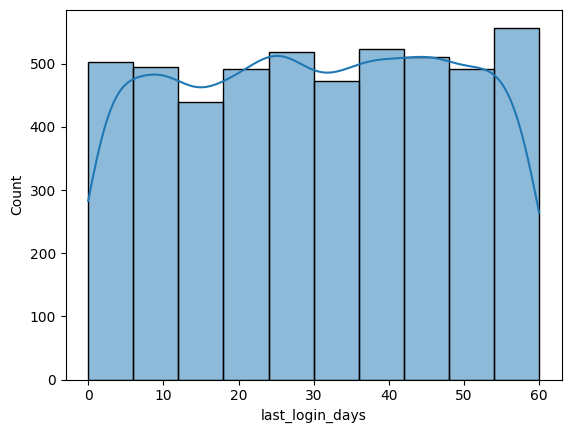

In [ ]:

sns.histplot(data=df, x="last_login_days", bins=10, kde=True)
plt.show()

In [ ]:
# Verificando Correlação linear de variáveis numéricas
print(
    "Pearson:", df["last_login_days"].corr(
        df["churned"], method="pearson"
    ).round(2)
)
print(
    "Spearman:", df["last_login_days"].corr(
        df["churned"], method="spearman"
    ).round(2)
)

Pearson: 0.47
Spearman: 0.47


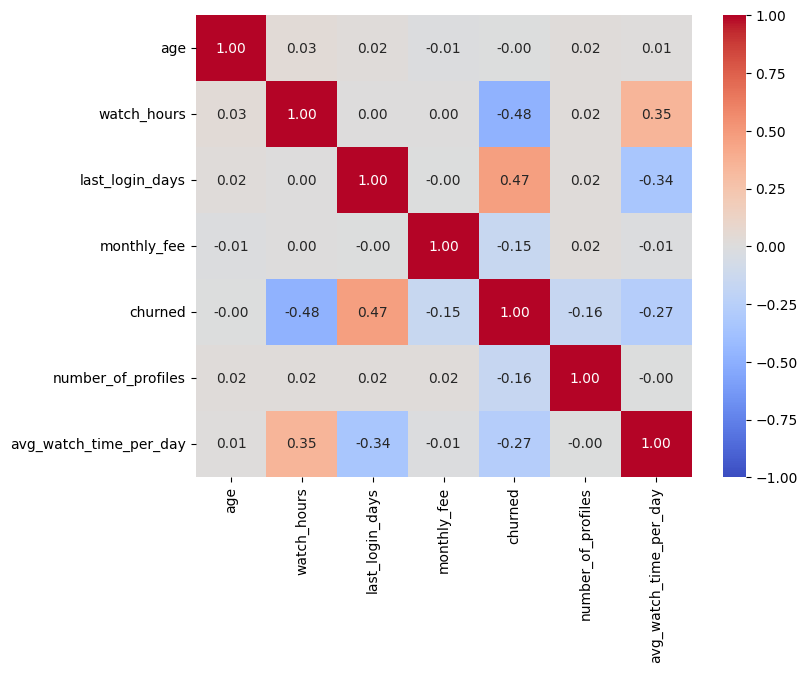

In [ ]:
# Verificando Correlação linear de variáveis numéricas com Heatmap

num_columns = df.select_dtypes(include="number").columns.tolist()
matrix_corr = df[num_columns].corr(method="pearson")

plt.figure(figsize=(8,6))

sns.heatmap(
    matrix_corr,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)
plt.show()

In [7]:
df["churned"].value_counts(dropna=False)

,count
churned,
1,2515
0,2485


In [8]:
df.groupby("churned")["last_login_days"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
churned,,,,,,
0,2485,21.77,19.0,16.16,0,60
1,2515,38.31,41.0,14.75,0,60


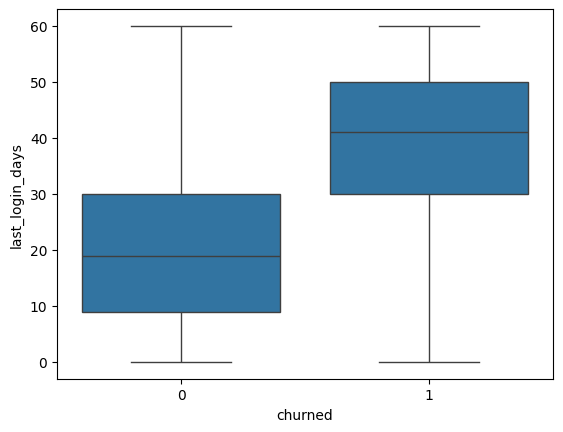

In [9]:
sns.boxplot(
    data=df,
    x="churned",
    y="last_login_days"
)
plt.title="Last Login Days by Churn Status"
plt.xlabel="Churned"
plt.ylabel="Days since last login"
plt.show()

In [10]:
display(df.dtypes.to_frame("dtype"))


,dtype
customer_id,object
age,int64
gender,object
subscription_type,object
watch_hours,float64
last_login_days,int64
region,object
device,object
monthly_fee,float64
churned,int64


In [ ]:
quality_assesment = pd.DataFrame({
    "misisng_count": df.isnull().sum(),
    "missing_pct":(df.isnull().mean() * 100).round(2)
})

quality_assesment.sort_values("missing_pct",ascending=False)


: 

In [12]:
print(
    "Duplicated rows:", df.duplicated().sum()
)

Duplicated rows: 0


In [13]:
for col in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{col}")
    print("Valores únicos:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(15))


customer_id
Valores únicos: 5000
customer_id
a9b75100-82a8-427a-a208-72f24052884a    1
49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b    1
4d71f6ce-fca9-4ff7-8afa-197ac24de14b    1
d3c72c38-631b-4f9e-8a0e-de103cad1a7d    1
4e265c34-103a-4dbb-9553-76c9aa47e946    1
d8079475-5be7-47e9-8782-ceb7ff61395e    1
8e63450a-13d6-4e83-bbb5-6aebde9152cb    1
02387681-8c42-462a-807a-de0168c73b38    1
0bcaad0c-545c-4ee1-85a6-75e165f39361    1
eae6439e-8cdf-4258-ab49-c493925b927a    1
45a03ce3-26d0-4cd5-a9bd-22d42490b612    1
9df43ad1-d6ee-44d0-a79b-c8ab444f10bf    1
4690bf9c-b828-44d3-bdb6-f91b10668288    1
0aac0e54-7d40-4cf2-abe4-45f3ff73f5ff    1
e2a75072-5f48-47ed-a533-eb1b0301aad9    1
Name: count, dtype: int64

gender
Valores únicos: 3
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

subscription_type
Valores únicos: 3
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

region
Valores únicos: 6
region
South America    873
Europe  

In [14]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,5000,5000,a9b75100-82a8-427a-a208-72f24052884a,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,5000.0,NaN,NaN,NaN,43.8474,15.501128,18.0,30.0,44.0,58.0,70.0
gender,5000,3,Female,1711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
subscription_type,5000,3,Premium,1693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
watch_hours,5000.0,NaN,NaN,NaN,11.64945,12.014654,0.01,3.3375,8.0,16.03,110.4
last_login_days,5000.0,NaN,NaN,NaN,30.0898,17.536078,0.0,15.0,30.0,45.0,60.0
region,5000,6,South America,873,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device,5000,5,Tablet,1048,NaN,NaN,NaN,NaN,NaN,NaN,NaN
monthly_fee,5000.0,NaN,NaN,NaN,13.6834,3.692062,8.99,8.99,13.99,17.99,17.99
churned,5000.0,NaN,NaN,NaN,0.503,0.500041,0.0,0.0,1.0,1.0,1.0


In [15]:
df.groupby("subscription_type")["churned"].mean() * 100


,churned
subscription_type,
Basic,61.830223
Premium,43.709392
Standard,45.443499


In [16]:
churn_rate = df["churned"].mean() * 100
print(f"Overall Churn Rate: {churn_rate:.2f}%")

Overall Churn Rate: 50.30%


In [17]:
bins = [0, 10, 20, 30, 40, 50, 60]
labels = ["0-10d", "11-20d", "21-30d", "31-40d", "41-50d", "51-60d"]
df["inactivity_group"] = pd.cut(df["last_login_days"], bins=bins, labels=labels)
inactivity_churn = df.groupby("inactivity_group", observed=False)["churned"].mean() * 100
print("\nChurn by Inactivity Cohort (%):\n", inactivity_churn)


Churn by Inactivity Cohort (%):
 inactivity_group
0-10d     18.280872
11-20d    26.709677
21-30d    35.335689
31-40d    72.506083
41-50d    78.054567
51-60d    74.626866
Name: churned, dtype: float64


In [18]:
# Verificando proporção de ocorrência de variável categórica dentro do mesmo grupo (Subscription_Type X Churned), sem indice -- Normalize = "index"
pd.crosstab(
    df["subscription_type"],
    df["churned"],
    margins=True
)



churned,0,1,All
subscription_type,,,
Basic,634,1027,1661
Premium,953,740,1693
Standard,898,748,1646
All,2485,2515,5000


In [19]:
# Verificando proporção de ocorrência de variável categórica dentro do mesmo grupo (Subscription_Type X Churned)
churn_by_subscription = pd.crosstab(
    df["subscription_type"],
    df["churned"],
    normalize="index"
)

churn_by_subscription.round(2)

churned,0,1
subscription_type,,
Basic,0.38,0.62
Premium,0.56,0.44
Standard,0.55,0.45


In [ ]:
# Teste de Qui - Quadrado para verificar assoociação de variáveis dependentes

contingency_table = pd.crosstab(
    df["subscription_type"],
    df["churned"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Qui-quadrado: {chi2:.4f}")
print(f"Graus de liberdade: {dof}")
print(f"p-valor: {p_value:.6f}")

Qui-quadrado: 133.2778
Graus de liberdade: 2
p-valor: 0.000000


In [ ]:

#Frequencia Esperada - usando Pandas

expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print(expected_df.round(2))
print("Menor frequência esperada:", expected_df.min().min())
print(
    "Proporção de células com frequência esperada >= 5:",
    (expected_df >= 5).to_numpy().mean()
)

churned                 0       1
subscription_type                
Basic              825.52  835.48
Premium            841.42  851.58
Standard           818.06  827.94
Menor frequência esperada: 818.062
Proporção de células com frequência esperada >= 5: 1.0


In [22]:
# Teste V de Cramér, que mede a intensidade da associação entre subscription_type e churned.

n = contingency_table.to_numpy().sum()
min_dimension = min(contingency_table.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dimension))

print(f"V de Cramér: {cramers_v:.4f}")


V de Cramér: 0.1633
